# Collecting, cleaning and storing Bluesky posts about a company

What do people say about a company on social media? This demonstration follows the first steps of a text mining project, the ones that take the most time in a real data project:

1. **collect** public posts that mention the company, on the [Bluesky](https://bsky.app) social network;
2. **anonymize** them, as soon as they are collected;
3. **clean** them, to keep only the words that carry meaning;
4. **store** them, in a file and in a database;
5. draw a first **business view** from them: what are people talking about, and when?

In the CRISP-DM method, these are the data understanding and data preparation phases.

To run it: *Runtime > Run all* in Colab, *Run All* in a Codespace. If Bluesky doesn't answer, the notebook falls back on synthetic posts, written for the demonstration with the same noise as real posts. **The outputs stored in this notebook come from these synthetic posts**: in class, the demonstration runs live on Bluesky.

## 0. Setup and parameters

The `wordcloud` library draws the word cloud at the end (Colab already has it).

In [1]:
!pip install -q --no-warn-script-location wordcloud

The company studied, the posts' language and how many to collect. Change `QUERY` to study another company: the rest of the notebook follows. `LIVE = False` goes straight to the synthetic posts, without calling Bluesky.

In [2]:
import hashlib
import re
import sqlite3
import time
import unicodedata
from collections import Counter
from itertools import pairwise

import matplotlib.pyplot as plt
import pandas as pd
import requests
import spacy
from wordcloud import WordCloud

QUERY = "Ikea"  # the company studied
LANG = "en"  # the posts' language
MAX_POSTS = 1000  # how many posts to collect
LIVE = True  # False: the synthetic posts, without calling Bluesky

## 1. Collecting the posts

Bluesky is an open social network: its search API, the site's search bar for a program, answers without an account. We ask it for the most recent posts that contain the company's name, 100 per page, going back in time, with a one-second pause between two pages so as not to overload the service.

In [3]:
API_URL = "https://api.bsky.app/xrpc/app.bsky.feed.searchPosts"


def search_posts(query, lang, max_posts):
  """The most recent posts that contain `query`, page by page."""
  posts = {}
  until = None
  while len(posts) < max_posts:
    params = {"q": query, "lang": lang, "sort": "latest", "limit": 100}
    if until:
      params["until"] = until  # the next page: the posts published before
    response = requests.get(API_URL, params=params, timeout=30)
    response.raise_for_status()
    page = response.json()["posts"]
    new = {post["uri"]: post for post in page if post["uri"] not in posts}
    if not new:
      break
    posts.update(new)
    until = min(post["indexedAt"] for post in page)
    time.sleep(1)  # a polite pause between two requests
  return list(posts.values())[:max_posts]

**Anonymization.** A post is personal data under the GDPR: its author can be identified. Counting words doesn't require knowing who speaks. So, as soon as they are collected, we keep neither the author's handle, nor their identifier, nor their display name, and we mask the mentions of other accounts (`@…`) in the text: this is the data minimization principle, collecting only what the project needs.

This is only pseudonymization: a post's text can be found with a simple search. The data is still personal, to be kept only for the project's duration.

In [4]:
MENTION = re.compile(r"@[\w-]+(?:\.[\w-]+)*")  # @handle.bsky.social


def anonymize(post):
  """The post without its author: no handle, identifier or display name."""
  return {
    # a key to spot duplicates, unreadable
    "post_id": hashlib.sha256(post["uri"].encode()).hexdigest()[:16],
    "created_at": post["record"]["createdAt"],
    "text": MENTION.sub("@anonymous", post["record"].get("text", "")),
    "likes": post.get("likeCount", 0),
    "reposts": post.get("repostCount", 0),
    "replies": post.get("replyCount", 0),
  }

The collection. If the API doesn't answer, or returns fewer than 100 posts, we load the synthetic posts: posts about Ikea written for the demonstration, mentions already masked.

In [5]:
FALLBACK_URL = (
  "https://github.com/shuuchuu/datasets/raw/refs/heads/main/"
  f"bluesky-ikea-synthetic/posts-{LANG}.csv"
)
MIN_POSTS = 100

collected = []
if LIVE:
  try:
    collected = [anonymize(post) for post in search_posts(QUERY, LANG, MAX_POSTS)]
  except requests.RequestException as error:
    print(f"Bluesky's API doesn't answer ({error}).")

if len(collected) >= MIN_POSTS:
  posts = pd.DataFrame(collected)
  print(f"{len(posts)} posts collected live from Bluesky.")
else:
  posts = pd.read_csv(FALLBACK_URL)
  QUERY = "Ikea"  # the synthetic posts' company
  print(f"{len(collected)} posts collected live: switching to the synthetic posts.")
  print(f"{len(posts)} synthetic posts about Ikea, written for the demonstration.")

posts["created_at"] = pd.to_datetime(
  posts["created_at"], utc=True, format="ISO8601", errors="coerce"
)
first, last = posts["created_at"].min(), posts["created_at"].max()
print(f"From {first:%Y-%m-%d} to {last:%Y-%m-%d}.")
posts[["created_at", "text", "likes"]].head()

0 posts collected live: switching to the synthetic posts.
428 synthetic posts about Ikea, written for the demonstration.
From 2026-08-20 to 2026-10-17.


,created_at,text,likes
0,2026-10-17 22:55:50.530000+00:00,"Exchange refused without a receipt, and the bo...",0
1,2026-10-17 22:04:19.913000+00:00,"The store moved the aisles again, I'm lost 🤯 (...",0
2,2026-10-17 22:01:15.228000+00:00,The plant balls are better than the classic me...,0
3,2026-10-17 21:45:39.847000+00:00,🔥 DEAL 🔥 Ikea furniture up to 50% off! Full li...,0
4,2026-10-17 21:20:16.688000+00:00,"The Lack really is the do-it-all furniture, I ...",3


## 2. Cleaning the texts

To a computer, a text is only a sequence of characters. To count the words that matter, we split it into words with spaCy, a language processing library that knows that "don't" makes two, and we remove the noise: links, mentions, emojis, punctuation, digits, and stop words ("the", "of", "and"), very frequent but empty of content, as well as the company's name, which is everywhere. We lowercase everything, so that "Sofa" and "sofa" are the same word, and keep the word of hashtags (#kitchen becomes kitchen).

In [6]:
nlp = spacy.blank(LANG)  # spaCy's splitting into words, for the language
STOP_WORDS = nlp.Defaults.stop_words  # and its stop words
URL = re.compile(r"https?://\S+|\b(?:[\w-]+\.)+[a-z]{2,}/\S*")


def strip_accents(word):
  return unicodedata.normalize("NFKD", word).encode("ascii", "ignore").decode()


# the company's name, with or without accents ("ikéa")
COMPANY = {strip_accents(word) for word in QUERY.lower().split()}


def clean(text):
  """The words of a post that carry meaning, lowercased."""
  text = URL.sub(" ", text.lower())  # links
  text = re.sub(r"@\S+", " ", text)  # mentions
  words = [
    token.text
    for token in nlp(text)
    if token.is_alpha  # no emoji, punctuation, digit or #
    and not token.is_stop
    and len(token) > 2
    and strip_accents(token.text) not in COMPANY
  ]
  return " ".join(words)


posts["clean_text"] = posts["text"].map(clean)

Before and after, on three posts that contain a link, a mention or a hashtag:

In [7]:
examples = posts[posts["text"].str.contains(r"[@#/]")].drop_duplicates("text").head(3)
for text, cleaned in zip(examples["text"], examples["clean_text"]):
  print(f"BEFORE: {text}")
  print(f"AFTER:  {cleaned}")
  print()

BEFORE: The store moved the aisles again, I'm lost 🤯 (Seattle) Noted. Worth a read: ikea.com/us/en/p/pax-70/
AFTER:  store moved aisles lost seattle noted worth read

BEFORE: The plant balls are better than the classic meatballs, I stand by it #ikea
AFTER:  plant balls better classic meatballs stand

BEFORE: 🔥 DEAL 🔥 Ikea furniture up to 50% off! Full list of deals here 👉 https://bit.ly/3xKdeal #ikea #deals
AFTER:  deal furniture list deals deals



Then we remove three kinds of posts:

- those in another language: the language Bluesky gives a post is the one of its author's app settings, not always the post's. We keep those with at least as many stop words of the studied language than of the other one;
- those the cleaning left empty (a lone link, emojis);
- duplicates: the search doesn't return reposts (shares), but automated accounts publish the same text several times, which would inflate its words' counts.

In [8]:
OTHER_STOP_WORDS = spacy.blank("en" if LANG == "fr" else "fr").Defaults.stop_words


def in_language(text):
  """True if the post has at least as many stop words of LANG as of the other one."""
  words = re.findall(r"\w+", text.lower())
  own = sum(word in STOP_WORDS for word in words)
  return own >= sum(word in OTHER_STOP_WORDS for word in words)


collected = len(posts)
posts = posts[posts["text"].map(in_language)]
other_language = collected - len(posts)
posts = posts[posts["clean_text"] != ""]
empty = collected - other_language - len(posts)
posts = posts.drop_duplicates(subset="clean_text").reset_index(drop=True)
print(f"{collected} posts collected")
print(f"- {other_language} in another language")
print(f"- {empty} empty after cleaning")
print(f"- {collected - other_language - empty - len(posts)} duplicates")
print(f"= {len(posts)} posts to analyze")

428 posts collected
- 26 in another language
- 11 empty after cleaning
- 59 duplicates
= 332 posts to analyze


## 3. Storing the data

Two common formats: a CSV file, which Excel opens and which is easy to share, and an SQLite database, queried in SQL, the language of databases. In a company, this data would go to the data warehouse or the data lake, with the collection's date and the search made, so that the analysis can be redone.

In [9]:
posts.to_csv("posts.csv", index=False)

connection = sqlite3.connect("posts.db")
posts.to_sql("posts", connection, if_exists="replace", index=False)
pd.read_sql("SELECT COUNT(*) AS posts FROM posts", connection)

,posts
0,332


An SQL query: the number of posts and likes per day, over the collection's last seven days.

In [10]:
query = """
SELECT date(created_at) AS day, COUNT(*) AS posts, SUM(likes) AS likes
FROM posts
GROUP BY day
ORDER BY day DESC
LIMIT 7
"""
pd.read_sql(query, connection)

,day,posts,likes
0,2026-10-17,7,3
1,2026-10-16,4,0
2,2026-10-15,4,2
3,2026-10-14,5,15
4,2026-10-13,2,5
5,2026-10-12,4,12
6,2026-10-11,4,35


## 4. A first business view

The most frequent words tell what people talk about when they talk about the company.

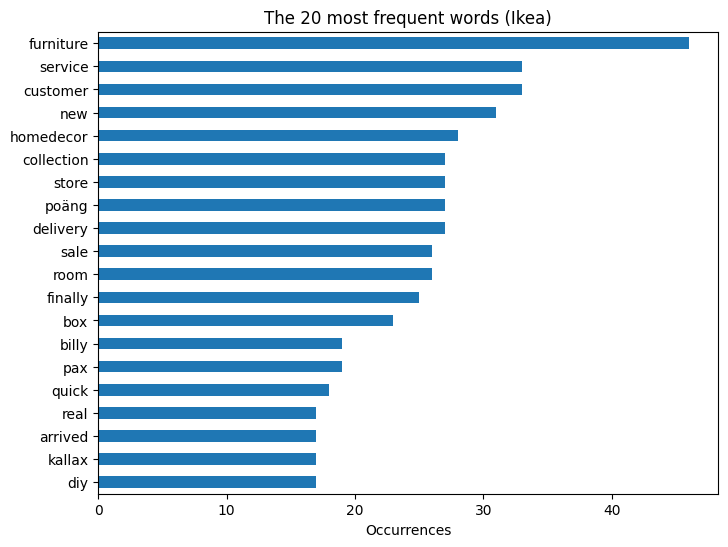

In [11]:
words = Counter(word for text in posts["clean_text"] for word in text.split())
top_words = pd.Series(dict(words.most_common(20))).sort_values()
top_words.plot.barh(figsize=(8, 6), title=f"The 20 most frequent words ({QUERY})")
plt.xlabel("Occurrences")
plt.show()

Bigrams, two words in a row, give more context than a single word ("customer service", "delivery delay").

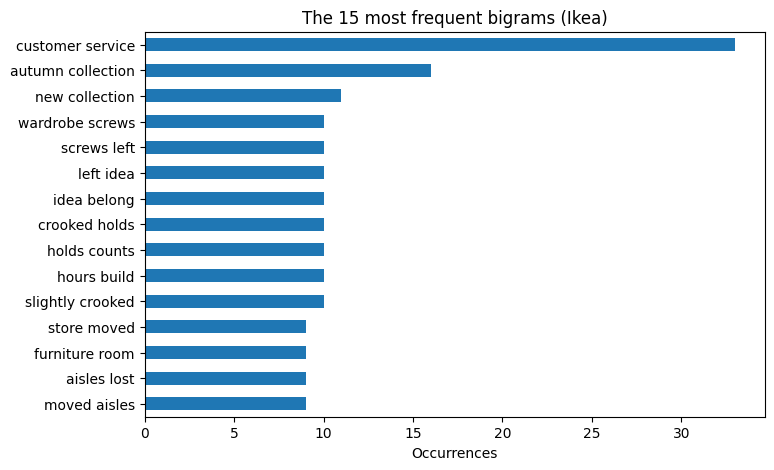

In [12]:
bigrams = Counter(
  f"{a} {b}" for text in posts["clean_text"] for a, b in pairwise(text.split())
)
top_bigrams = pd.Series(dict(bigrams.most_common(15))).sort_values()
top_bigrams.plot.barh(figsize=(8, 5), title=f"The 15 most frequent bigrams ({QUERY})")
plt.xlabel("Occurrences")
plt.show()

The number of posts per day: a peak signals an event worth looking into (an announcement, a controversy, a product recall).

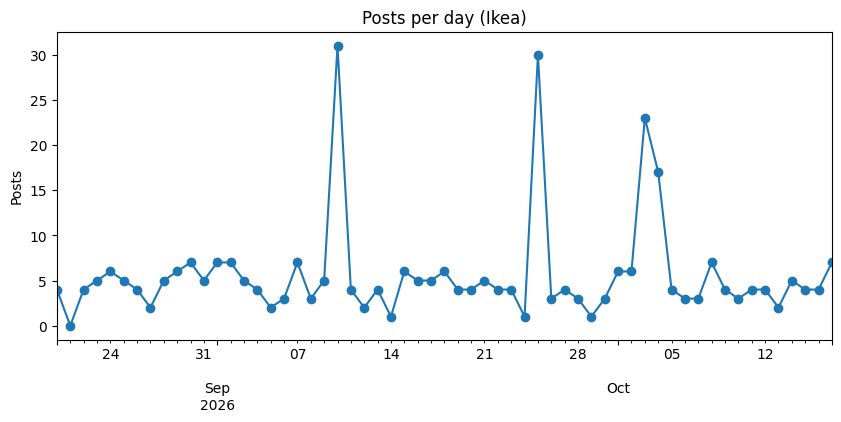

In [13]:
per_day = posts.set_index("created_at").resample("D").size()
per_day.plot(figsize=(10, 4), marker="o", title=f"Posts per day ({QUERY})")
plt.xlabel("")
plt.ylabel("Posts")
plt.show()

And a word cloud, where a word's size follows its frequency: less precise than a chart, but telling.

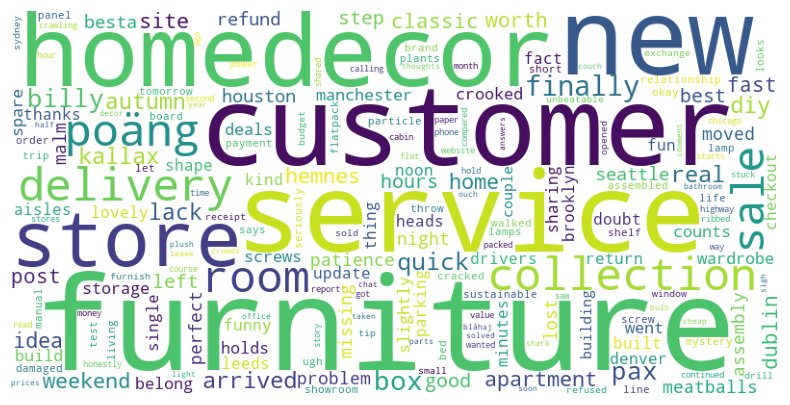

In [14]:
cloud = WordCloud(width=800, height=400, background_color="white")
cloud.generate_from_frequencies(words)
plt.figure(figsize=(10, 5))
plt.imshow(cloud)
plt.axis("off")
plt.show()

## Going further

- **Limits**: Bluesky's users are not the company's customers, a few hundred recent posts are only a sample, and a frequent word doesn't tell whether an opinion is positive or negative.
- **Next steps**: sentiment analysis, topic detection, a stop word list of the project's own (common words such as "good" or "make"), lemmatization ("sofa" and "sofas" counted together), an automated daily collection to follow trends and raise alerts.
- **GDPR**: a legal basis (usually legitimate interest), a retention period, informing the people and their right to object, all planned before collecting.